# Chapter 12 | Worked solutions

*Efficient Execution*

## Goal

Work through all eleven exercises, from a response timeline to an experimental
protocol. The central idea is to retain enough information to combine score
tiles without storing all their entries at once. Keep track of what a number
measures: response time, aggregate throughput, stored bytes, or transferred bytes.
Exercises 9-11 are optional. Both PDF editions contain every explanation and
figure; the notebook edition also includes code and recorded outputs.

## Setup

Run inside `transformers-book` on CPU, with the repository requirements plus
`matplotlib` and Jupyter installed. No model or dataset download is needed.
The saved run uses Python 3.12 and NumPy 2.4. Counts and masks are exact;
floating-point checks specify their tolerances.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch12_efficient" / "model.py"
    )
    if model_path.is_file():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )

## 1. Draw a response timeline

Prefill consumes all four prompt tokens and builds their key--value history.
The logits at the last prompt position select the first response token, $y_1$.
It is available after 80 ms. The next call consumes $y_1$, appends its key
and value, and selects $y_2$. Each later call consumes the previously selected ID.

| Work just completed | Input consumed | Token selected | Elapsed time |
| --- | --- | --- | --- |
| Prefill | Four prompt tokens | $y_1$ | 80 ms |
| Decode 1 | $y_1$ | $y_2$ | 92 ms |
| Decode 2 | $y_2$ | $y_3$ | 104 ms |
| Decode 3 | $y_3$ | $y_4$ | 116 ms |
| Decode 4 | $y_4$ | $y_5$ | 128 ms |

Output $y_i$ is selected at $80+(i-1)12$ ms. Five outputs require only four
calls after prefill. Feeding back the final $y_5$ would begin work on a sixth
prediction. The **time to first token is 80 ms**, and the **total execution
time is 128 ms**. Both start at the beginning of prefill. Sampling, queuing,
and network time are outside this exercise.

In [2]:
response_tokens = 5
token_times_ms = 80 + np.arange(response_tokens) * 12
np.testing.assert_array_equal(token_times_ms, [80, 92, 104, 116, 128])
print("Token-selection times (ms):", token_times_ms)
print("Time to first token:", token_times_ms[0], "ms")
print("Total execution time:", token_times_ms[-1], "ms")

Token-selection times (ms): [ 80  92 104 116 128]
Time to first token: 80 ms
Total execution time: 128 ms


## 2. Compare two batches

For one request, the run delivers five output tokens in 128 ms. For three
batched requests, prefill selects three first tokens together at 100 ms.
Each following 24 ms call advances all three requests by one token. The
selection times for each request are 100, 124, 148, 172, and 196 ms.

| Setup | Output tokens across run | Completion time per request | Aggregate output throughput |
| --- | --- | --- | --- |
| One request | 5 | 128 ms | $5/0.128=39.0625$ tokens/s |
| Three requests in one batch | 15 | 196 ms | $15/0.196\approx76.5306$ tokens/s |

The numerator counts generated tokens only; the denominator includes prefill.
The batch delivers three times as many tokens in $196/128=1.53125$ times the
elapsed time. Its aggregate rate rises, but each user waits 68 ms longer.
Dividing 196 ms by three does not give the wait experienced by a user:
all three requests run concurrently and each finishes at 196 ms.

Per-request completion time answers how long one user waits for the whole
response. Time to first token answers when text starts appearing: 80 ms
versus 100 ms here. Throughput answers how much output the system delivers
across its users per second. None of these invented numbers is a GPU benchmark.

In [3]:
for batch, prefill_ms, decode_ms in [(1, 80, 12), (3, 100, 24)]:
    times = prefill_ms + np.arange(5) * decode_ms
    throughput = batch * 5 / (times[-1] / 1000)
    print(f"B={batch}: times {times} ms; {throughput:.4f} tokens/s")
assert 100 + 4 * 24 == 196
assert 80 + 4 * 12 == 128

B=1: times [ 80  92 104 116 128] ms; 39.0625 tokens/s
B=3: times [100 124 148 172 196] ms; 76.5306 tokens/s


## 3. Count one intermediate

One head has a score for each query--key pair, so its full score array
contains $2048^2=4194304$ entries. Across 16 heads, that is 67,108,864
entries for one layer and one sequence. Multiply by bytes per entry:

| Bytes per score | Bytes for one head | Bytes for 16 heads | MiB for 16 heads |
| --- | --- | --- | --- |
| 2 | 8388608 | 134217728 | 128 |
| 4 | 16777216 | 268435456 | 256 |

A MiB is $2^{20}=1048576$ bytes. The shape stays fixed, so doubling the
entry size doubles the storage. A causal mask blocks some pairs but does
not remove their slots from a materialized full square array.

This excludes the softmax probability array if it is also materialized,
and the key and value arrays. It also excludes the query and output arrays,
model weights, and other workspaces. Peak total memory depends on which
arrays coexist, not just the size of one tensor.

In [4]:
entries_per_head = 2048**2
for bytes_per_score, expected_mib in [(2, 128), (4, 256)]:
    total = 16 * entries_per_head * bytes_per_score
    assert total == expected_mib * 2**20
    print(bytes_per_score, "bytes/score:", total, "bytes =", total // 2**20, "MiB")

2 bytes/score: 134217728 bytes = 128 MiB
4 bytes/score: 268435456 bytes = 256 MiB


## 4. Follow a changing maximum

Call scores $(0,\ln3)$ with values $(2,4)$ tile A, and score $\ln6$ with
value 1 tile B. After a nonempty set of keys, the state is

$$
m=\max_j s_j,\qquad \ell=\sum_j e^{s_j-m},\qquad u=\sum_j e^{s_j-m}v_j.
$$

Both sums use the same reference $m$. If it rises to $m'$, the identity
$e^{s_j-m'}=e^{s_j-m}e^{m-m'}$ gives one multiplier for every old term.
Rescale both old sums, then add the incoming terms at the new reference.

**A, then B.** Tile A sets $m=\ln3$. Its shifted weights are $(1/3,1)$,
so $\ell=4/3$ and $u=2/3+4=14/3$. Tile B raises the maximum to $\ln6$.
The old sums receive a factor $e^{\ln3-\ln6}=1/2$, while B adds weight
one and weighted value one:

$$
\ell'=\tfrac12\tfrac43+1=\tfrac53,\qquad
u'=\tfrac12\tfrac{14}3+1=\tfrac{10}3.
$$

The final output is $(10/3)/(5/3)=2$.

**B, then A.** Tile B starts at $(m,\ell,u)=(\ln6,1,1)$. When A arrives,
the maximum stays at $\ln6$ and the old-state multiplier is one. A's new
shifted weights are $(1/6,1/2)$:

$$
\ell'=1+\tfrac16+\tfrac12=\tfrac53,\qquad
u'=1+\tfrac16(2)+\tfrac12(4)=\tfrac{10}3.
$$

| Tile order | State after first tile $(m,\ell,u)$ | Multiplier on old sums at second tile | Final state |
| --- | --- | --- | --- |
| A, B | $(\ln3,4/3,14/3)$ | $1/2$ | $(\ln6,5/3,10/3)$ |
| B, A | $(\ln6,1,1)$ | $1$ | $(\ln6,5/3,10/3)$ |

Direct softmax uses unshifted weights $(1,3,6)$, so the result is
$(1\cdot2+3\cdot4+6\cdot1)/(1+3+6)=20/10=2$. The online sums are both
one-sixth of the unshifted sums; their ratio is unchanged. Different tile
orders may change the last floating-point digits, but not the mathematical answer.

The independently normalized tile answers are $14/4=3.5$ for A and
$6/6=1$ for B. Their ordinary average is **2.25**, which is wrong.
A and B have exponential masses 4 and 6, respectively. The correct
combination is $(4\cdot3.5+6\cdot1)/(4+6)=2$. The relative masses are
lost if we retain only each tile's normalized answer.

In [5]:
from examples.ch12_efficient.model import online_update

def empty_online_state():
    return np.array([-np.inf]), np.zeros(1), np.zeros((1, 1))

tiles = {
    "A": (np.array([[0., np.log(3.)]]), np.array([[2.], [4.]])),
    "B": (np.array([[np.log(6.)]]), np.array([[1.]])),
}
for order in [("A", "B"), ("B", "A")]:
    state = empty_online_state()
    print("Order", order)
    for name in order:
        scores, values = tiles[name]
        state = online_update(*state, scores, values)
        print(name, "m, ell, u =", state[0][0], state[1][0], state[2][0, 0])
    np.testing.assert_allclose([state[0][0], state[1][0], state[2][0, 0]],
                               [np.log(6), 5/3, 10/3], atol=1e-12, rtol=0)
    np.testing.assert_allclose(state[2] / state[1][:, None], [[2]], atol=1e-12, rtol=0)
print("Wrong average of tile answers:", (3.5 + 1) / 2)
print("Correct weighted combination:", (4 * 3.5 + 6 * 1) / 10)

Order ('A', 'B')
A m, ell, u = 1.0986122886681098 1.3333333333333333 4.666666666666667
B m, ell, u = 1.791759469228055 1.6666666666666667 3.333333333333334
Order ('B', 'A')
B m, ell, u = 1.791759469228055 1.0 1.0
A m, ell, u = 1.791759469228055 1.6666666666666667 3.333333333333334
Wrong average of tile answers: 2.25
Correct weighted combination: 2.0


## 5. Check an uneven grid

There are five query rows and eleven key columns. Each cell
represents one query–key score. A tile contains up to two rows
and four columns, so a tile that reaches the bottom or right edge
may be smaller. We use zero-based row and column indices.

| Query rows | Keys 0–3 | Keys 4–7 | Keys 8–10 |
| :--- | :--- | :--- | :--- |
| 0–1 | A · $2\times4$ | B · $2\times4$ | C · $2\times3$ (partial) |
| 2–3 | D · $2\times4$ | E · $2\times4$ | F · $2\times3$ (partial) |
| 4 | G · $1\times4$ (partial) | H · $1\times4$ (partial) | I · $1\times3$ (partial) |

Each letter labels one tile. Tile C is partial because the final
column group contains only three keys. Tile G is partial because
the final row group contains just one query. Tile I has both
short edges. The colored diagram below shows each score location and its tile.


Counting the whole grid gives $5\times11=55$ scores. Counting by
tile also gives $4(8)+2(6)+2(4)+3=55$, since every score belongs
to exactly one tile. The largest tile holds $2\times4=8$ scores.
Pass the lengths and then the two tile dimensions to
`score_workspace` to check these two counts.

In [6]:
from examples.ch12_efficient.model import score_workspace

full_count, largest_tile_count = score_workspace(5, 11, 2, 4)
tile_counts = np.outer([2, 2, 1], [4, 4, 3])

np.testing.assert_array_equal(tile_counts.sum(), full_count)
np.testing.assert_array_equal(tile_counts.max(), largest_tile_count)

print("Number of scores in each tile")
print(tile_counts)
print(f"Full grid: {full_count} scores")
print(f"Largest tile: {largest_tile_count} scores")

Number of scores in each tile
[[8 8 6]
 [8 8 6]
 [4 4 3]]
Full grid: 55 scores
Largest tile: 8 scores


The sum counts every score location in the unmasked grid, even if
the algorithm computes those scores at different times. It is also
how many elements a single materialized score grid would store.
The maximum counts the score elements in one tile at its largest.
When tiles are processed sequentially, the algorithm can carry
the running softmax state forward and release each tile's score
array before moving on. It still visits all 55 scores in this
example. Both counts are in elements. Multiplying by the score
dtype's bytes per element gives the bytes for the corresponding
score array alone. Inputs, outputs, masks, running accumulators,
and any separate weight arrays also require space.

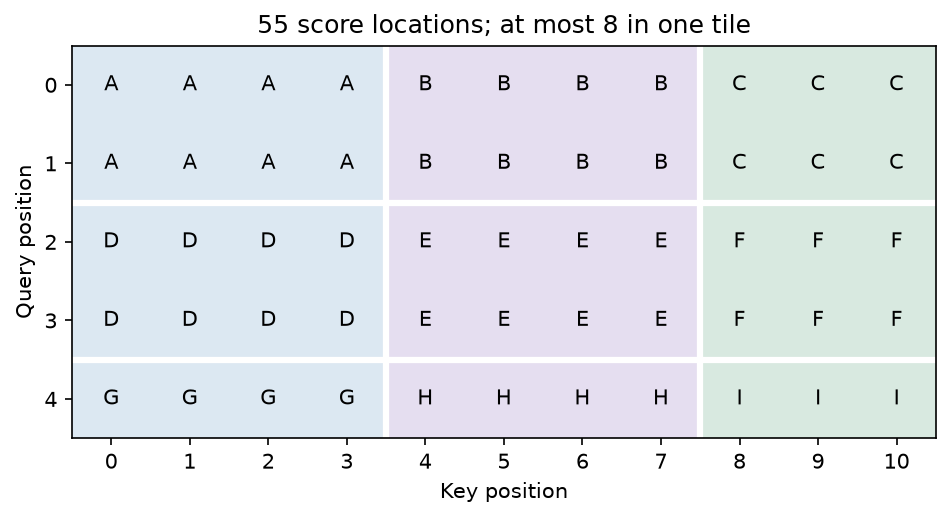

In [7]:
import io
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import Image, display

def show_plot(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

ids = np.empty((5, 11), dtype=int)
for row in range(5):
    for col in range(11):
        ids[row, col] = (row // 2) * 3 + col // 4
fig, ax = plt.subplots(figsize=(8.2, 3.4))
ax.imshow(ids, cmap=ListedColormap(["#dce8f2", "#e5def0", "#d8e9e0"] * 3),
          vmin=0, vmax=8)
for (row, col), tile_id in np.ndenumerate(ids):
    ax.text(col, row, chr(65 + tile_id), ha="center", va="center")
for boundary in [3.5, 7.5]: ax.axvline(boundary, color="white", lw=3)
for boundary in [1.5, 3.5]: ax.axhline(boundary, color="white", lw=3)
ax.set(xticks=range(11), yticks=range(5), xlabel="Key position",
       ylabel="Query position", title="55 score locations; at most 8 in one tile")
show_plot(fig)

## 6. Change the tile shape

Three queries each have one feature, and the four keys and values
each have one feature. Without a mask, every query reads all four
keys. Each score is the query–key dot product divided by the
square root of the key width. The width here is one, so for a
scalar query $q_i$ the scores are $q_i(0,1,-1,2)$.

Take the first query, $q_0=1$. Its scores are $(0,1,-1,2)$.
The values at the same positions are $(4,1,3,2)$, so the
output is the sum of the four values multiplied by their
normalized exponential weights.

$$
y_0
= \frac{4+e+3e^{-1}+2e^2}{1+e+e^{-1}+e^2}
\approx 1.9694644227.
$$

We will compute a dense reference for all three rows. It
subtracts the largest score in each row before exponentiating.
This common shift leaves the softmax unchanged, since its factor
cancels between the numerator and denominator.

In [8]:
from examples.ch12_efficient.model import tiled_attention

tile_queries = np.array([[1.0], [2.0], [3.0]])
tile_keys = np.array([[0.0], [1.0], [-1.0], [2.0]])
tile_values = np.array([[4.0], [1.0], [3.0], [2.0]])

dense_scores = tile_queries @ tile_keys.T
shifted_scores = dense_scores - dense_scores.max(axis=1, keepdims=True)
dense_weights = np.exp(shifted_scores)
dense_weights /= dense_weights.sum(axis=1, keepdims=True)
dense_output = dense_weights @ tile_values

with np.printoptions(precision=10):
    print("Dense output:", dense_output[:, 0])

Dense output: [1.9694644227 1.9167694979 1.9575193731]


During tiled attention, each query carries a running maximum $m$,
an exponential sum $\ell$, and a value-weighted sum $u$. After a
set of scores has been seen, those sums contain $e^{s-m}$ and
$e^{s-m}v$ terms respectively. If a new tile raises $m$, both
accumulated sums are rescaled to the new reference before its
contributions are added. Every partition processes the same
scores and values in this unmasked example. Once all keys have
been seen, the ratio $u/\ell$ therefore gives the same result in
exact arithmetic.

Compare each output with the dense reference and with the
$(1,1)$ result. We use float64, absolute tolerance $10^{-12}$,
and relative tolerance zero, since regrouping a sum can change
the last digits in floating-point arithmetic.

In [9]:
tile_shapes = [(1, 1), (2, 3), (3, 4)]
tile_outputs = {}
for query_tile, key_tile in tile_shapes:
    shape = (query_tile, key_tile)
    tile_outputs[shape] = tiled_attention(
        tile_queries, tile_keys, tile_values, query_tile, key_tile,
    )

for shape, output in tile_outputs.items():
    np.testing.assert_allclose(
        output, tile_outputs[(1, 1)], rtol=0, atol=1e-12
    )
    np.testing.assert_allclose(output, dense_output, rtol=0, atol=1e-12)
    full, largest = score_workspace(3, 4, *shape)
    error = np.max(np.abs(output - dense_output))
    print(f"Tile {shape} | full grid {full} | largest tile {largest}")
    with np.printoptions(precision=10):
        print(f"  Output {output[:, 0]} | max difference {error:.3g}")

Tile (1, 1) | full grid 12 | largest tile 1
  Output [1.9694644227 1.9167694979 1.9575193731] | max difference 2.22e-16
Tile (2, 3) | full grid 12 | largest tile 6
  Output [1.9694644227 1.9167694979 1.9575193731] | max difference 2.22e-16
Tile (3, 4) | full grid 12 | largest tile 12
  Output [1.9694644227 1.9167694979 1.9575193731] | max difference 2.22e-16


All three partitions agree within the stated tolerance. They each
cover a full grid of twelve scores. With $(1,1)$, a tile holds
just one score. With $(2,3)$, the two query groups contain two
and one rows, and the two key groups contain three and one
columns. The four tiles contain $6,2,3,1$ scores respectively,
so the largest has six. The $(3,4)$ tile covers the whole grid
and holds all twelve scores at once. These are counts for the
score array alone. Tile dimensions can change the size and number
of intermediate arrays, so the largest score tile alone cannot
tell us the peak memory or which shape runs fastest.

The common output vector is approximately $(1.9694644227, 1.9167694979, 1.9575193731)$. The largest score tiles contain 1, 6, and 12 entries, respectively; the full grid always contains 12.

## 7. Pass through an empty tile

Imagine a query whose first score tile contains two future keys.
The dot products in that tile are $4$ and $7$, and the corresponding
values are $8$ and $5$. The Boolean mask `[[False, False]]`
excludes both keys. Neither their scores nor their values should
enter the softmax calculation.

For one query, the running state contains a maximum score $m$,
a denominator $\ell$, and a weighted numerator $u$. The
denominator adds up the exponential weights of permitted keys.
The numerator adds the same weights times the corresponding
values. The two sums use scores measured relative to $m$.
The initial state has $m=-\infty$ and $\ell=u=0$ because
it has seen no permitted keys. The state arrays have shapes
`[1]`, `[1]`, and `[1, 1]`, respectively. The numerator
has an extra axis for its one value feature.

Here the first tile leaves that state unchanged. Internally the
helper substitutes $-\infty$ for each masked score. For an empty
row it uses zero as the temporary subtraction reference, so
exponentiating a masked score gives $\exp(-\infty-0)=0$. This
avoids subtracting $-\infty$ from itself and still records
$-\infty$ as the stored maximum.

In [10]:
from examples.ch12_efficient.model import online_update

def empty_online_state():
    return np.array([-np.inf]), np.zeros(1), np.zeros((1, 1))

blocked_state = online_update(
    *empty_online_state(),
    scores=np.array([[4, 7]]),
    values=np.array([[8], [5]]),
    allowed=np.zeros((1, 2), dtype=bool),
)
blocked_m, blocked_ell, blocked_u = blocked_state
np.testing.assert_array_equal(blocked_m, [-np.inf])
np.testing.assert_array_equal(blocked_ell, [0.0])
np.testing.assert_array_equal(blocked_u, [[0.0]])
print(f"Blocked tile  m={blocked_m[0]}, ell={blocked_ell[0]}, "
      f"u={blocked_u[0, 0]}")
print("Output undefined because the denominator is zero.")

Blocked tile  m=-inf, ell=0.0, u=0.0
Output undefined because the denominator is zero.


The next tile contains one permitted key, with score $2$ and
value $9$. The first finite maximum is $m=2$. The new key has
weight $\exp(2-2)=1$, giving $\ell=1$ and $u=9$. The old state
contributes zero because it contains no earlier permitted key.
The output becomes defined when the first valid tile makes
$\ell$ positive. In a full tiled read, divide only after all
tiles have contributed, since later valid keys can change the
final ratio.

In [11]:
first_key_state = online_update(
    *blocked_state, scores=np.array([[2]]), values=np.array([[9]])
)
first_m, first_ell, first_u = first_key_state
np.testing.assert_array_equal(first_m, [2.0])
np.testing.assert_array_equal(first_ell, [1.0])
np.testing.assert_array_equal(first_u, [[9.0]])
print(f"Valid tile    m={first_m[0]}, ell={first_ell[0]}, "
      f"u={first_u[0, 0]}")
assert np.all(first_ell > 0)
output = first_u / first_ell[:, None]
np.testing.assert_array_equal(output, [[9.0]])
print(f"Output after checking denominator  {output[0, 0]}")

Valid tile    m=2.0, ell=1.0, u=9.0
Output after checking denominator  9.0


## 8. Trace a rectangular causal mask

There are two query rows and five key rows. The query row
within the current chunk has index $i\in\{0,1\}$. Its position
in the whole sequence is $p=\text{query\_start}+i$. The key
history starts at zero, so a key with index $j$ is visible
exactly when $j\le p$. In particular, the query can read the
key at its own position.

All query and key vectors are zero. Every permitted score
therefore equals zero, and every permitted key gets the same
weight. With $r$ permitted keys, each has softmax weight
$\exp(0)/(r\exp(0))=1/r$. The output is the mean of the visible
values, which makes the effect of the mask easy to check by hand.

| Query start | Query row | Absolute position | Readable keys | Output |
| ---: | ---: | ---: | :--- | :--- |
| 0 | 0 | 0 | $[0]$ | $1$ |
| 0 | 1 | 1 | $[0,1]$ | $(1+3)/2=2$ |
| 3 | 0 | 3 | $[0,1,2,3]$ | $(1+3+7+2)/4=3.25$ |
| 3 | 1 | 4 | $[0,1,2,3,4]$ | $(1+3+7+2+9)/5=4.4$ |

With one query row and two key columns per tile, the key
slices are `[0, 1]`, `[2, 3]`, and `[4]`. For absolute
position 0, the first tile admits only key 0 and the later
tiles admit no keys. For absolute position 3, the first two
tiles are fully visible, and the last tile is still in the
future. For a chunk starting at position 3, the causal boundary
shifts to key columns 3 and 4.

In [12]:
from examples.ch12_efficient.model import tiled_attention

offset_q = np.zeros((2, 1))
offset_k = np.zeros((5, 1))
offset_v = np.array([[1], [3], [7], [2], [9]], dtype=float)
key_indices = np.arange(len(offset_k))
expected = {0: [1.0, 2.0], 3: [3.25, 4.4]}

for start, expected_rows in expected.items():
    result = tiled_attention(
        offset_q, offset_k, offset_v, 1, 2,
        causal=True, query_start=start,
    )
    query_positions = start + np.arange(len(offset_q))
    allowed = key_indices[None, :] <= query_positions[:, None]
    means = [offset_v[row, 0].mean() for row in allowed]
    np.testing.assert_allclose(means, expected_rows, atol=1e-12, rtol=0)
    np.testing.assert_allclose(
        result[:, 0], expected_rows, atol=1e-12, rtol=0
    )
    print(f"query_start = {start}")
    for p, row, value in zip(query_positions, allowed, result[:, 0]):
        readable = key_indices[row].tolist()
        print(f"  query {p} reads {readable}, output {value:.2f}")

query_start = 0
  query 0 reads [0], output 1.00
  query 1 reads [0, 1], output 2.00
query_start = 3
  query 3 reads [0, 1, 2, 3], output 3.25
  query 4 reads [0, 1, 2, 3, 4], output 4.40


The two calls pass the same vectors to the same implementation.
Only the absolute position of each query changes. The outputs
at start 3 incorporate more of the history because those rows
are later in the sequence. If a chunk actually belongs at
positions 3 and 4, passing a start of zero wrongly removes
three keys from each query. The float64 comparisons above
allow an absolute difference of $10^{-12}$ and use zero
relative tolerance.

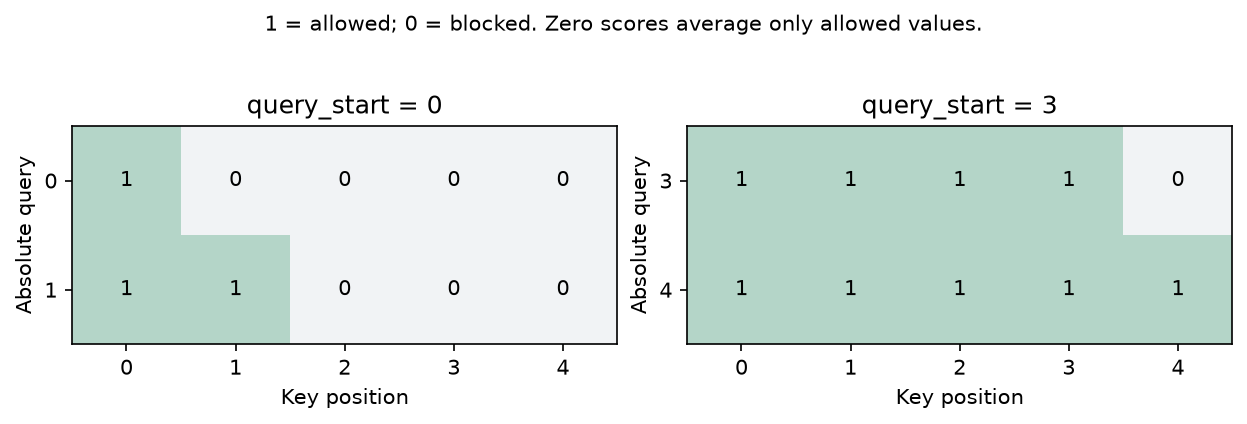

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(8.2, 2.8), constrained_layout=True)
for ax, start in zip(axes, [0, 3]):
    positions = start + np.arange(2)
    allowed = np.arange(5)[None, :] <= positions[:, None]
    ax.imshow(allowed, cmap=ListedColormap(["#f1f3f5", "#b4d5c8"]), vmin=0, vmax=1)
    ax.set(xticks=range(5), yticks=range(2), yticklabels=positions,
           xlabel="Key position", ylabel="Absolute query", title=f"query_start = {start}")
    for (row, col), value in np.ndenumerate(allowed):
        ax.text(col, row, int(value), ha="center", va="center")
fig.suptitle("1 = allowed; 0 = blocked. Zero scores average only allowed values.", fontsize=10)
show_plot(fig)

## 9. Stress the exponentials (optional)

Give the first score tile $[800,799]$ and the second tile
$[801]$. The corresponding values are $(1,3)$ and $(5)$.
The exponential of a score around 800 exceeds the largest
representable float64 number. Online softmax avoids that
calculation by subtracting the running maximum before
exponentiating.

Write $a=e^{-1}$ and $b=e^{-2}$. The first tile sets $m=800$.
The two shifted scores are $0$ and $-1$, so
$\ell=1+a$ and $u=1+3a$. When the second tile raises the
maximum to 801, multiply both old sums by
$\exp(800-801)=a$. The new score equals the new maximum and
adds weight $1$ and weighted value $5$. The final state is

$$
m=801,\qquad
\ell=a(1+a)+1=1+a+b,\qquad
u=a(1+3a)+5=5+a+3b.
$$

The direct stable calculation subtracts the final maximum
from all three scores at once. It exponentiates the shifted
row $(-1,-2,0)$ and gives the same ratio
$(5+a+3b)/(1+a+b)$.

Adding 50 to all the scores also adds 50 to every finite
running maximum. The shifted scores within each tile and
the difference between the old and new maxima stay the
same. Predict that both finite maxima increase by 50 and
that both pairs of sums, as well as the final output, agree
between the two runs.

In [14]:
stress_scores = np.array([[800.0, 799.0, 801.0]])
stress_values = np.array([[1.0], [3.0], [5.0]])

def trace_online(scores):
    state = empty_online_state()
    states = []
    for start, stop in ((0, 2), (2, 3)):
        state = online_update(
            *state, scores[:, start:stop], stress_values[start:stop]
        )
        maximum, denominator, numerator = state
        states.append([maximum[0], denominator[0], numerator[0, 0]])
    return np.array(states)

base_trace = trace_online(stress_scores)
shifted_trace = trace_online(stress_scores + 50)
for shift, trace in ((0, base_trace), (50, shifted_trace)):
    print(f"Score shift +{shift}")
    for tile, (m, ell, u) in enumerate(trace, start=1):
        print(f"  tile {tile}  m={m:.0f}  ell={ell:.9f}  u={u:.9f}")
    assert np.isfinite(trace[-1]).all()
    assert trace[-1, 1] > 0

Score shift +0
  tile 1  m=800  ell=1.367879441  u=2.103638324
  tile 2  m=801  ell=1.503214724  u=5.773885291
Score shift +50
  tile 1  m=850  ell=1.367879441  u=2.103638324
  tile 2  m=851  ell=1.503214724  u=5.773885291


In [15]:
def direct_stable_output(scores):
    weights = np.exp(scores - scores.max(axis=1, keepdims=True))
    return (weights @ stress_values) / weights.sum(axis=1, keepdims=True)

a, b = np.exp([-1.0, -2.0])
hand_sums = [[1 + a, 1 + 3*a], [1 + a + b, 5 + a + 3*b]]
np.testing.assert_array_equal(base_trace[:, 0], [800.0, 801.0])
np.testing.assert_array_equal(shifted_trace[:, 0] - base_trace[:, 0], 50)
np.testing.assert_allclose(
    base_trace[:, 1:], hand_sums, atol=1e-12, rtol=0
)
np.testing.assert_allclose(
    shifted_trace[:, 1:], base_trace[:, 1:], atol=1e-12, rtol=0
)
online_outputs = [trace[-1, 2] / trace[-1, 1]
                  for trace in (base_trace, shifted_trace)]
direct_outputs = [direct_stable_output(stress_scores + shift)[0, 0]
                  for shift in (0, 50)]
np.testing.assert_allclose(
    online_outputs, direct_outputs, atol=1e-12, rtol=0
)
np.testing.assert_allclose(
    online_outputs[0], online_outputs[1], atol=1e-12, rtol=0
)
for shift, online, direct in zip((0, 50), online_outputs, direct_outputs):
    print(f"+{shift:<2}  online {online:.12f}  direct {direct:.12f}")

+0   online 3.841024969440  direct 3.841024969440
+50  online 3.841024969440  direct 3.841024969440


The stored maxima move from $(800,801)$ to $(850,851)$.
The denominator and numerator after each tile agree across
the two runs, and the final states are finite. Both outputs
match the directly stabilized calculation within an absolute
tolerance of $10^{-12}$ with zero relative tolerance in
float64. The same comparison works without forming an
exponential of any of the original large scores.

The output for both score shifts is approximately $3.841024969440$. Subtracting the maximum prevents overflow; shifting all scores by 50 changes the stored reference but not the relative weights.

## 10. Explain a changing bottleneck (optional)

With $n$ prompt positions, prefill has $n$ queries and $n$ keys per head:
a score grid of shape $n\times n$. The causal mask permits the diagonal
and everything below it, for $n(n+1)/2$ pairs. A full allocation still has
$n^2$ slots, including blocked entries.

The first cached call consumes the token selected after prefill. This token
has absolute position $n$. Its layer computes one query and appends one
key and value to the $n$ stored positions. The query reads keys $0$ through
$n$, including its own key. Its score grid is **$1\times(n+1)$**.
For a four-position prompt, write 1 for an allowed read and 0 for a blocked read:

| Stage / query | Key 0 | Key 1 | Key 2 | Key 3 | Key 4 |
| --- | --- | --- | --- | --- | --- |
| Prefill, query 0 | 1 | 0 | 0 | 0 | Not present |
| Prefill, query 1 | 1 | 1 | 0 | 0 | Not present |
| Prefill, query 2 | 1 | 1 | 1 | 0 | Not present |
| Prefill, query 3 | 1 | 1 | 1 | 1 | Not present |
| First cached call, query 4 | 1 | 1 | 1 | 1 | 1 |

At $n=2048$, the full prefill array has 4,194,304 entries per head, whereas
the first cached call has 2,049. Eliminating complete intermediate arrays
therefore offers much less score-storage saving for that cached call.
It still reads the KV history. The full decoder also reads model weights,
runs projections and feed-forward layers, and dispatches kernels. At batch
size one, those costs can take a larger fraction of the step. The grid
shapes suggest an explanation; measurements must establish the bottleneck.

First collect a kernel trace that separates attention, projections, and
feed-forward work for each stage. Keep the model, input, batch size,
precision, and device fixed while switching the attention implementation.
Second, measure the attention kernels' HBM read and write traffic in
separate profiling runs. A large drop in prefill writes with little change
in decode reads would support the proposed explanation. If attention speeds
up but occupies only a small part of the step, the trace explains the small
overall improvement.

For the timing calculation, other work occupies $100-20=80$ ms. Halving
attention leaves $20/2=10$ ms, so the new step takes **90 ms**. The overall
speedup is $100/90\approx1.111$, or a 10% reduction in elapsed time.
Even zero attention time would leave 80 ms. These are illustrative timings,
not measured results for the NumPy example.

In [16]:
n = 2048
print("Prefill full grid:", (n, n), n*n, "entries")
print("Prefill allowed pairs:", n*(n+1)//2)
print("First cached grid:", (1, n+1), n+1, "entries")
old_ms, attention_ms = 100, 20
new_ms = old_ms - attention_ms + attention_ms / 2
assert new_ms == 90
print("New step:", new_ms, "ms; overall speedup:", old_ms / new_ms)

Prefill full grid: (2048, 2048) 4194304 entries
Prefill allowed pairs: 2098176
First cached grid: (1, 2049) 2049 entries
New step: 90.0 ms; overall speedup: 1.1111111111111112


## 11. Plan a fair kernel comparison (optional)

This is a proposed measurement protocol, not a benchmark that has been run.
Compare causal prefill attention on already projected $Q$, $K$, and $V$.
The materializing path writes full scores and probabilities to device memory;
the fused path carries tile data and running row statistics. In both paths,
query $i$ may read keys 0 through $i$, including its own key.

Use prompt lengths 512, 2048, and 4096, batch size two, eight heads, and
head width 64. Choose one NVIDIA A100 GPU. Use FP16 inputs and outputs with
FP32 softmax accumulation in both paths. Record intermediate formats too:
a full score array stored in FP32 has four bytes per entry. Keep the tensor
layout, head grouping, scale, and mask fixed; disable dropout. Prepare the
same seeded, unit-scale projected arrays for both paths at each length.
Record the software versions and the kernels that actually execute. An
automatically fused reference would change the intended comparison.

Check correctness before timing. On a short prefix, compare each query and
head with a float64 materializing reference that subtracts the row maximum
before exponentiating. Verify the causal mask and perturb a future value
to ensure earlier outputs remain unchanged. At each timed length, compare
outputs on the same inputs. For these unit-scale examples, a proposed
starting tolerance is $|x-y|\leq2\cdot10^{-3}+2\cdot10^{-3}|y|$ per output
coordinate. Record maximum absolute differences and investigate failures
before timing. This tolerance is an experimental choice for these inputs,
not a universal bound for FP16 attention.

Time the attention operation. Inputs are already resident on the device
when the timer starts; stop when the output is ready there. Include score
calculation, masking, softmax, and the weighted sum, including intermediate
writes, reads, tile processing, and any workspace allocation done per call.
If constructing a mask is part of the call, include it. Leave input and
output projections and token sampling outside this interval. A separate
full-model prefill measurement can show the effect on time to first token.

Warm up both paths at each shape. Run 30 paired trials with their order
alternating. Synchronize the device before starting and before stopping a
wall-clock timer; this includes host work within the measured call. Report
the median and interquartile range for each length. Do not mix asynchronous
launch time with completed device execution time.

Measure memory in separate runs. Once inputs are resident, reset the peak
allocated-memory counter and record the peak above that baseline. Use an
allocation trace to separate temporary workspaces from the common output
buffer at the same instants. Report reserved memory separately, since an
allocator can retain unused blocks after tensors are released.

To test the data-movement explanation, collect hardware counters in separate
warmed runs when the device supports them. Sum bytes read from and written
to HBM by all kernels in one attention call. Compare at identical shapes.
Peak workspace counts bytes stored at once; traffic counts bytes transferred
over time. A reduction in both elapsed time and transferred bytes supports
the explanation. Timing alone cannot distinguish that effect from better
scheduling or fewer arithmetic operations.

## Checks

All eleven exercises have complete solutions. The executed checks cover
response times, aggregate throughput, exact byte counts, both tile orders,
partial tiles, output invariance across tile shapes, empty masked rows,
absolute query positions, and large-score stability. Numerical equality
uses a declared tolerance; memory counts specify which arrays they include.

## Next Steps

Change a tile shape or a query offset, predict the answer, then rerun.
Treat the NumPy implementation as an inspectable correctness model.
Its CPU timing does not measure a fused GPU kernel. The original
[FlashAttention paper](https://arxiv.org/abs/2205.14135) and
[FlashAttention-2 paper](https://arxiv.org/abs/2307.08691) explain the GPU schedules.